In [1]:
%matplotlib widget
import os
import numpy as np
import pandas as pd
import glob2 as gb
import matplotlib.pyplot as plt
import matplotlib as mpl
import torch
import time
from sklearn.preprocessing import MaxAbsScaler

mpl.rcParams['keymap.pan'] = ['d']
mpl.rcParams['keymap.zoom'] = ['z']


In [2]:
top20 = ['0441', '0013', '0089', '0152', '0021', '0061', '0340', '0418', '0170', '0080', '0435', '0224', '0379', '0351', '0147', '0439', '0338', '0336', '0208', '0516']
cwd = os.getcwd()
phase_name = 'alpha'

perturb_dirs = [cwd, 'TOPAS', phase_name, 'ml_data_generation','randomstates']
expt_dirs =  [cwd, 'TOPAS', phase_name, 'experimental_refinement']
pawley_dirs = [cwd, 'TOPAS', phase_name, 'subgrouptree_refinement']

bin_edges_filename = f'{phase_name}_bin_edges_C0p0008.txt'
expt_hkl_filename = 'd_Ip_expt_VC_P1_latparams.dat'
expt_xy_filename = 'simulated_xy_expt_VC_P1_latparams.xy'

perturb_path = os.path.join(*perturb_dirs)
expt_path = os.path.join(*expt_dirs)
pawley_path = os.path.join(*pawley_dirs)

# load bin edges
bin_edges_path = os.path.join(cwd, 'TOPAS', phase_name, 'alpha_bin_edges_C0p0008.txt')
bin_edges = torch.tensor(np.loadtxt(bin_edges_path))

# -------------------------------------------------------------------------------------------
# get xy data functions
# -------------------------------------------------------------------------------------------
def get_expt_xy(expt_path):
    expt_file = os.path.join(expt_path, expt_xy_filename)
    expt_xy = pd.read_csv(expt_file, sep='\s+', header = None, names = ['x','y'])
    return expt_xy

def get_xy_pawley(pawley_path, cifnumber):
    xy_path = os.path.join(pawley_path, f'cif{cifnumber}', f'cif{cifnumber}_xy.xy')
    xy = pd.read_csv(xy_path, sep='\s+', header = None, names = ['x','y'])
    return xy

def get_xy_perturb(perturb_path, cifnumber, statenumber):
    xy_path = os.path.join(perturb_path, f'cif{cifnumber}_randomstates', f'cif{cifnumber}_rs_{statenumber}_xy.xy')
    xy = pd.read_csv(xy_path, sep='\s+', header = None, names = ['x','y'])
    return xy

# -------------------------------------------------------------------------------------------
# get hkl data functions
# -------------------------------------------------------------------------------------------

def get_expt_hkl(expt_path, bin_edges, scale=None):
    expt_file = os.path.join(expt_path, expt_hkl_filename)
    hkl = pd.read_csv(expt_file, sep='\s+', header = None, names = ['d','i'])
    hkl_sorted = hkl.sort_values(by=['d'], ascending=True)
    hkl_tensor = torch.tensor(hkl_sorted.values, dtype=torch.double)
    hkl_binned = bin_tensor(hkl_tensor, bin_edges, scale)
    return hkl_binned

def get_hkl_pawley(pawley_path, cifnumber, bin_edges, scale=None):
    hkl_path = os.path.join(pawley_path, f'cif{cifnumber}', f'cif{cifnumber}_hkl.dat')
    hkl = pd.read_csv(hkl_path, sep='\s+', header = None, names = ['d','i'])
    hkl_sorted = hkl.sort_values(by=['d'], ascending=True)
    hkl_tensor = torch.tensor(hkl_sorted.values, dtype=torch.double)
    hkl_binned = bin_tensor(hkl_tensor, bin_edges, scale)
    return hkl_binned

def get_hkl_perturb(perturb_path, cifnumber, statenumber, bin_edges, scale=None):
    hkl_path = os.path.join(perturb_path, f'cif{cifnumber}_randomstates', f'cif{cifnumber}_rs_{statenumber}_hkl.dat')
    hkl = pd.read_csv(hkl_path, sep='\s+', header = None, names = ['d','i'])
    hkl_sorted = hkl.sort_values(by=['d'], ascending=True)
    hkl_tensor = torch.tensor(hkl_sorted.values, dtype=torch.double)
    hkl_tensor = bin_tensor(hkl_tensor, bin_edges, scale)
    return hkl_tensor

# -------------------------------------------------------------------------------------------
# modify hkl data functions
# -------------------------------------------------------------------------------------------

def bin_tensor(tensor_to_bin, bin_edges, scale):
    binned_tensor = torch.zeros_like(bin_edges)
    bucket_tensor = torch.bucketize(tensor_to_bin[:,0], bin_edges, right=False)
    for index,value in zip(bucket_tensor, tensor_to_bin[:,1]):
        binned_tensor[index] += value

    if scale != None:
        if scale == 'minmax':
            binned_scaled_tensor = minmaxscale_tensor(binned_tensor)
            return binned_scaled_tensor
        # if scale == 'maxabs':
        #     binned_scaled_tensor = maxabsscale_tensor(binned_tensor)
        #     return binned_scaled_tensor
        # if scale == 'minmax_maxabs':
        #     binned_scaled_tensor = minmax_maxabs_tensor(binned_tensor)
        #     return binned_scaled_tensor

    return binned_tensor

def minmaxscale_tensor(tensor):
    # Find the minimum and maximum values in the tensor
    min_val = torch.min(tensor)
    max_val = torch.max(tensor)
    # print(min_val)
    # print(max_val)
    # Scale the tensor to the range [0, 1]
    scaled_tensor = (tensor - min_val) / (max_val - min_val)
    
    return scaled_tensor

def maxabsscale_tensor(binned_tensor_list):
    local_data = torch.vstack(binned_tensor_list)
    scale_data = local_data.numpy()
    transformer = MaxAbsScaler().fit(scale_data)
    data_scaled = transformer.transform(scale_data)
    data_scaled_tensor = torch.tensor(data_scaled)
    scaled_tensor_list = list(data_scaled_tensor)
    return scaled_tensor_list
    


In [3]:
statenumber = '0001'

# get expt data
xy_expt = get_expt_xy(expt_path)
hkl_expt = get_expt_hkl(expt_path, bin_edges)

# get pawley data
xy_0548 = get_xy_pawley(pawley_path, '0548')
xy_0088 = get_xy_pawley(pawley_path, '0088')
xy_0547 = get_xy_pawley(pawley_path, '0547')

hkl_0548 = get_hkl_pawley(pawley_path, '0548', bin_edges)
hkl_0088 = get_hkl_pawley(pawley_path, '0088', bin_edges)
hkl_0547 = get_hkl_pawley(pawley_path, '0547', bin_edges)

# get perturbed data
pxy_0548 = get_xy_perturb(perturb_path, '0548', statenumber)
pxy_0088 = get_xy_perturb(perturb_path, '0088', statenumber)
pxy_0547 = get_xy_perturb(perturb_path, '0547', statenumber)

phkl_0548 = get_hkl_perturb(perturb_path, '0548', statenumber, bin_edges)
phkl_0088 = get_hkl_perturb(perturb_path, '0088', statenumber, bin_edges)
phkl_0547 = get_hkl_perturb(perturb_path, '0547', statenumber, bin_edges)





# Plot Perturbed XY & HKL

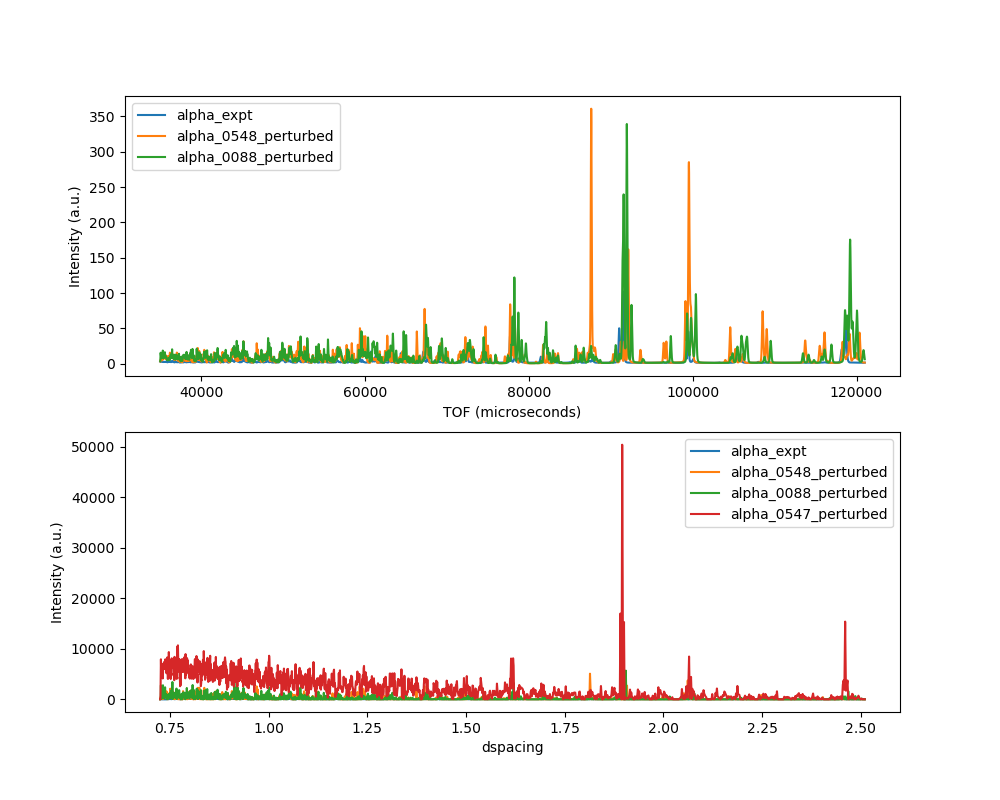

In [4]:
fig2, (ax_pxy, ax_phkl) = plt.subplots(2, figsize=(10,8))


#---------------------------------------------------------
# PLOT PERTURBED XY
ax_pxy.plot(xy_expt['x'], xy_expt['y'], label= f'{phase_name}_expt')
ax_pxy.plot(pxy_0548['x'], pxy_0548['y'], label=f'{phase_name}_0548_perturbed')
ax_pxy.plot(pxy_0088['x'], pxy_0088['y'], label=f'{phase_name}_0088_perturbed')
# ax_pxy.plot(pxy_0547['x'], pxy_0547['y'], label=f'{phase_name}_0547_perturbed')

ax_pxy.set_xlabel('TOF (microseconds)')
ax_pxy.set_ylabel('Intensity (a.u.)')
ax_pxy.legend()
# ax_pxy.legend(loc='center left', bbox_to_anchor=(.95, 0.5))

#---------------------------------------------------------
# PLOT BINNED HKLS - PERTURBED
ax_phkl.plot(bin_edges, hkl_expt, label = f'{phase_name}_expt')
ax_phkl.plot(bin_edges, phkl_0548, label=  f'{phase_name}_0548_perturbed')
ax_phkl.plot(bin_edges, phkl_0088, label=  f'{phase_name}_0088_perturbed')
ax_phkl.plot(bin_edges, phkl_0547, label = f'{phase_name}_0547_perturbed')

ax_phkl.set_xlabel('dspacing')
ax_phkl.set_ylabel('Intensity (a.u.)')
ax_phkl.legend()
# ax_phkl.legend(loc='center left', bbox_to_anchor=(.95, 0.5))

# Now that we scaled each tensor [0,1]
# Lets apply sklearn MaxAbs scaling across features 

# Plot Pawley XY & HKL

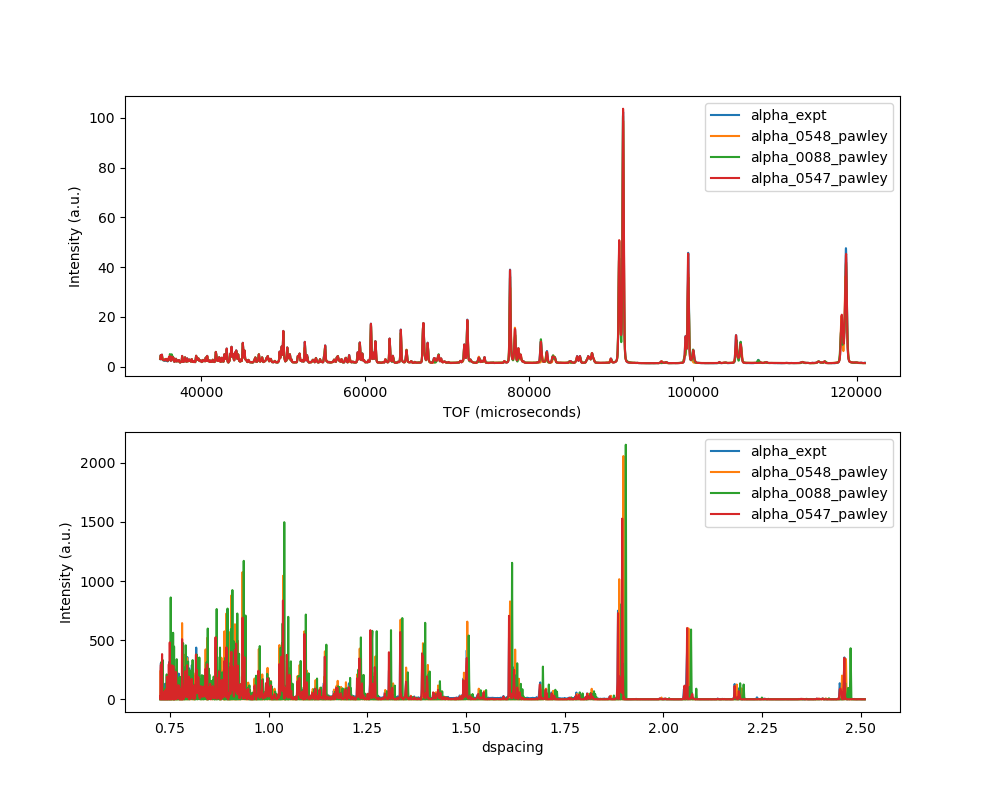

In [5]:
fig1, (ax_xy, ax_hkl) = plt.subplots(2, figsize=(10,8))

#---------------------------------------------------------
# PLOT PAWLEY XY
ax_xy.plot(xy_expt['x'], xy_expt['y'], label= f'{phase_name}_expt')
ax_xy.plot(xy_0548['x'], xy_0548['y'], label=f'{phase_name}_0548_pawley')
ax_xy.plot(xy_0088['x'], xy_0088['y'], label=f'{phase_name}_0088_pawley')
ax_xy.plot(xy_0547['x'], xy_0547['y'], label=f'{phase_name}_0547_pawley')

ax_xy.set_xlabel('TOF (microseconds)')
ax_xy.set_ylabel('Intensity (a.u.)')
ax_xy.legend()
# ax_xy.legend(loc='center left', bbox_to_anchor=(.95, 0.5))

#---------------------------------------------------------
# PLOT BINNED HKLS - PAWLEY
ax_hkl.plot(bin_edges, hkl_expt, label = f'{phase_name}_expt')
ax_hkl.plot(bin_edges, hkl_0548, label=  f'{phase_name}_0548_pawley')
ax_hkl.plot(bin_edges, hkl_0088, label=  f'{phase_name}_0088_pawley')
ax_hkl.plot(bin_edges, hkl_0547, label = f'{phase_name}_0547_pawley')

ax_hkl.set_xlabel('dspacing')
ax_hkl.set_ylabel('Intensity (a.u.)')
ax_hkl.legend()
# ax_hkl.legend(loc='center left', bbox_to_anchor=(.95, 0.5))


# Plot Perturbed HKL with various Scalings

(1.5, 1.75)

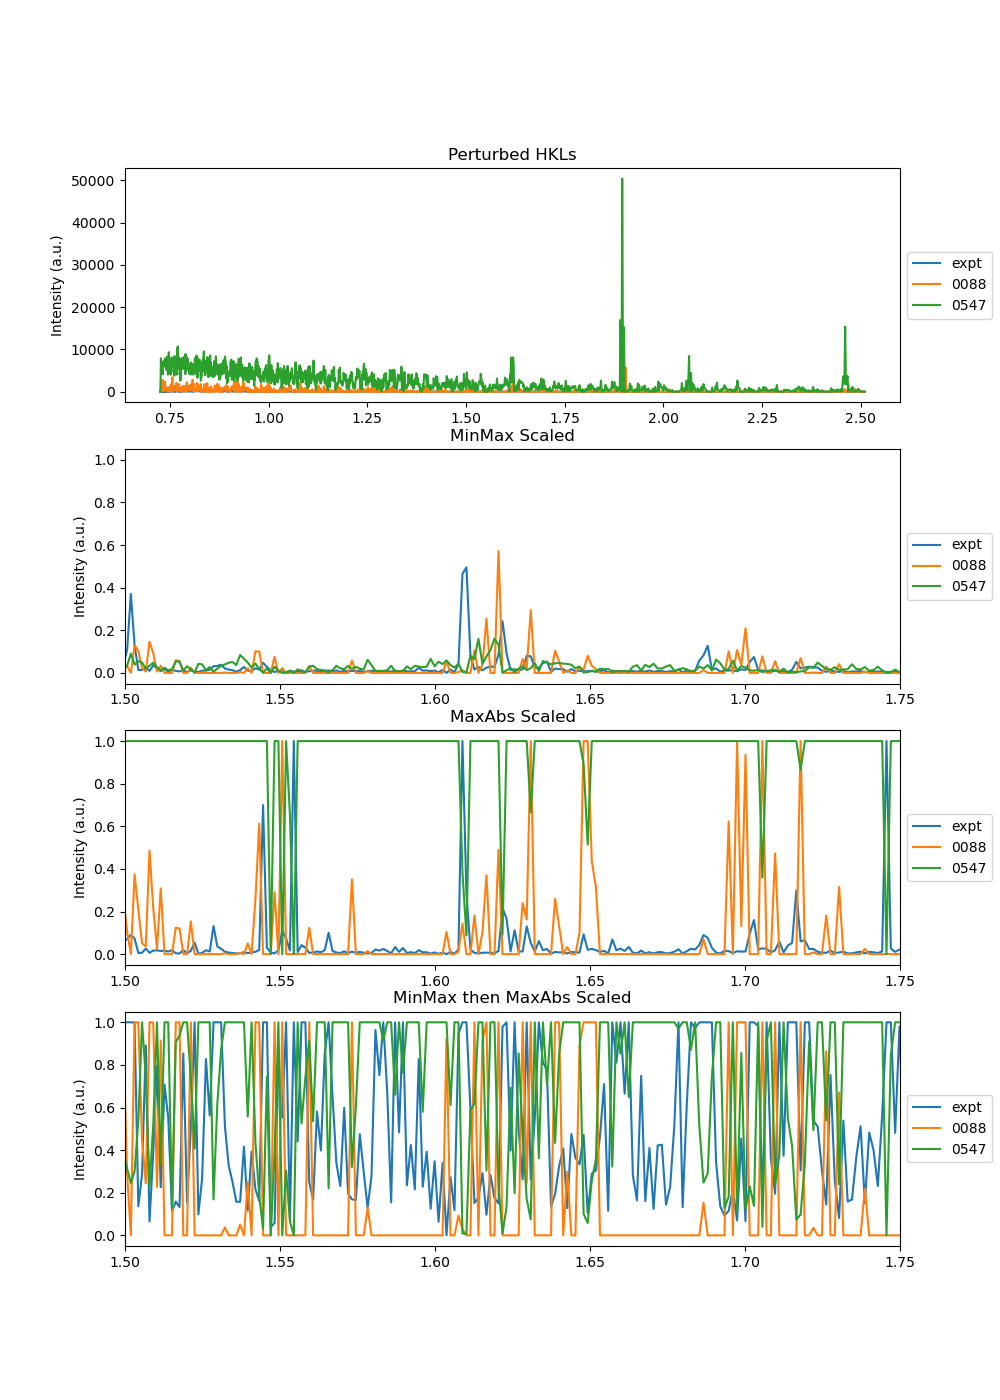

In [6]:
fig3, (plain_hkl, mm_hkl, maxabs_hkl, mm_maxabs_hkl) = plt.subplots(4, figsize=(10,14))
fig3.subplots_adjust(hspace=.2)
# minmax scaled hkls
mm_hkl_expt = get_expt_hkl(expt_path, bin_edges, scale='minmax')
mm_hkl_0548 = get_hkl_perturb(perturb_path, '0548', statenumber, bin_edges, scale='minmax')
mm_hkl_0088 = get_hkl_perturb(perturb_path, '0088', statenumber, bin_edges, scale='minmax')
mm_hkl_0547 = get_hkl_perturb(perturb_path, '0547', statenumber, bin_edges, scale='minmax')

# maxabs scaled hkls
ma_hkl_expt = get_expt_hkl(expt_path, bin_edges)
ma_hkl_0548 = get_hkl_perturb(perturb_path, '0548', statenumber, bin_edges)
ma_hkl_0088 = get_hkl_perturb(perturb_path, '0088', statenumber, bin_edges)
ma_hkl_0547 = get_hkl_perturb(perturb_path, '0547', statenumber, bin_edges)
ma_scaled_tensors = maxabsscale_tensor([ma_hkl_expt, ma_hkl_0548, ma_hkl_0088, ma_hkl_0547])
ma_hkl_expt = ma_scaled_tensors[0]
ma_hkl_0548 = ma_scaled_tensors[1]
ma_hkl_0088 = ma_scaled_tensors[2]
ma_hkl_0547 = ma_scaled_tensors[3]

# minmax then maxabs scaled hkls
mm_ma_scaled_tensors = maxabsscale_tensor([mm_hkl_expt, mm_hkl_0548, mm_hkl_0088, mm_hkl_0547])
mm_ma_hkl_expt = mm_ma_scaled_tensors[0]
mm_ma_hkl_0548 = mm_ma_scaled_tensors[1]
mm_ma_hkl_0088 = mm_ma_scaled_tensors[2]
mm_ma_hkl_0547 = mm_ma_scaled_tensors[3]

# plot scaled tensors in subplots
#---------------------------------------------------------
# plot unscaled
plain_hkl.plot(bin_edges, hkl_expt, label = f'expt')
# plain_hkl.plot(bin_edges, phkl_0548, label=  f'0548')
plain_hkl.plot(bin_edges, phkl_0088, label=  f'0088')
plain_hkl.plot(bin_edges, phkl_0547, label = f'0547')

plain_hkl.set_title(f'Perturbed HKLs')
# plain_hkl.set_xlabel('dspacing')
plain_hkl.set_ylabel('Intensity (a.u.)')
plain_hkl.legend(bbox_to_anchor = [1.0, .5], loc='center left')

#---------------------------------------------------------
# plot minmax scaled
mm_hkl.plot(bin_edges, mm_hkl_expt, label = f'expt')
# mm_hkl.plot(bin_edges, mm_hkl_0548, label = f'0548')
mm_hkl.plot(bin_edges, mm_hkl_0088, label = f'0088')
mm_hkl.plot(bin_edges, mm_hkl_0547, label = f'0547')

mm_hkl.set_title('MinMax Scaled')
# mm_hkl.set_xlabel('dspacing')
mm_hkl.set_ylabel('Intensity (a.u.)')
mm_hkl.legend(bbox_to_anchor = [1.0, .5], loc='center left')

#---------------------------------------------------------
# plot maxabs scaled 
maxabs_hkl.plot(bin_edges, ma_hkl_expt, label = f'expt')
# maxabs_hkl.plot(bin_edges, ma_hkl_0548, label = f'0548')
maxabs_hkl.plot(bin_edges, ma_hkl_0088, label = f'0088')
maxabs_hkl.plot(bin_edges, ma_hkl_0547, label = f'0547')

maxabs_hkl.set_title('MaxAbs Scaled')
# maxabs_hkl.set_xlabel('dspacing')
maxabs_hkl.set_ylabel('Intensity (a.u.)')
maxabs_hkl.legend(bbox_to_anchor = [1.0, .5], loc='center left')

#---------------------------------------------------------
# plot minmax then maxabs scaled 
mm_maxabs_hkl.plot(bin_edges, mm_ma_hkl_expt, label = f'expt')
# mm_maxabs_hkl.plot(bin_edges, mm_ma_hkl_0548, label = f'0548')
mm_maxabs_hkl.plot(bin_edges, mm_ma_hkl_0088, label = f'0088')
mm_maxabs_hkl.plot(bin_edges, mm_ma_hkl_0547, label = f'0547')

mm_maxabs_hkl.set_title('MinMax then MaxAbs Scaled')
# mm_maxabs_hkl.set_xlabel('dspacing')
mm_maxabs_hkl.set_ylabel('Intensity (a.u.)')
mm_maxabs_hkl.legend(bbox_to_anchor = [1.0, .5], loc='center left')

fig3.savefig('./scaled_hkls.tif')

lims = [1.5 , 1.75]
mm_hkl.set_xlim(lims)
maxabs_hkl.set_xlim(lims)
mm_maxabs_hkl.set_xlim(lims)


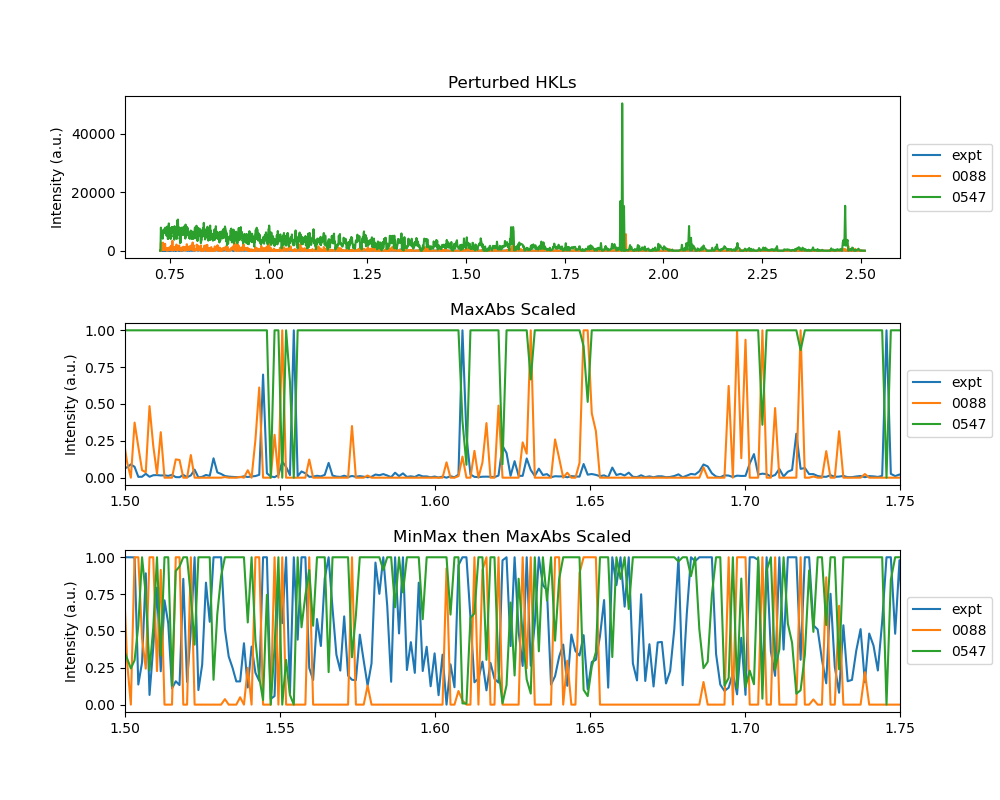

In [7]:
fig3, (plain_hkl, maxabs_hkl, mm_maxabs_hkl) = plt.subplots(3, figsize=(10,8))
fig3.subplots_adjust(hspace=.4)
# minmax scaled hkls
mm_hkl_expt = get_expt_hkl(expt_path, bin_edges, scale='minmax')
mm_hkl_0548 = get_hkl_perturb(perturb_path, '0548', statenumber, bin_edges, scale='minmax')
mm_hkl_0088 = get_hkl_perturb(perturb_path, '0088', statenumber, bin_edges, scale='minmax')
mm_hkl_0547 = get_hkl_perturb(perturb_path, '0547', statenumber, bin_edges, scale='minmax')

# maxabs scaled hkls
ma_hkl_expt = get_expt_hkl(expt_path, bin_edges)
ma_hkl_0548 = get_hkl_perturb(perturb_path, '0548', statenumber, bin_edges)
ma_hkl_0088 = get_hkl_perturb(perturb_path, '0088', statenumber, bin_edges)
ma_hkl_0547 = get_hkl_perturb(perturb_path, '0547', statenumber, bin_edges)
ma_scaled_tensors = maxabsscale_tensor([ma_hkl_expt, ma_hkl_0548, ma_hkl_0088, ma_hkl_0547])
ma_hkl_expt = ma_scaled_tensors[0]
ma_hkl_0548 = ma_scaled_tensors[1]
ma_hkl_0088 = ma_scaled_tensors[2]
ma_hkl_0547 = ma_scaled_tensors[3]

# minmax then maxabs scaled hkls
mm_ma_scaled_tensors = maxabsscale_tensor([mm_hkl_expt, mm_hkl_0548, mm_hkl_0088, mm_hkl_0547])
mm_ma_hkl_expt = mm_ma_scaled_tensors[0]
mm_ma_hkl_0548 = mm_ma_scaled_tensors[1]
mm_ma_hkl_0088 = mm_ma_scaled_tensors[2]
mm_ma_hkl_0547 = mm_ma_scaled_tensors[3]

# plot scaled tensors in subplots
#---------------------------------------------------------
# plot unscaled
plain_hkl.plot(bin_edges, hkl_expt, label = f'expt')
# plain_hkl.plot(bin_edges, phkl_0548, label=  f'0548')
plain_hkl.plot(bin_edges, phkl_0088, label=  f'0088')
plain_hkl.plot(bin_edges, phkl_0547, label = f'0547')

plain_hkl.set_title(f'Perturbed HKLs')
# plain_hkl.set_xlabel('dspacing')
plain_hkl.set_ylabel('Intensity (a.u.)')
plain_hkl.legend(bbox_to_anchor = [1.0, .5], loc='center left')

#---------------------------------------------------------
# plot minmax scaled
# mm_hkl.plot(bin_edges, mm_hkl_expt, label = f'expt')
# # mm_hkl.plot(bin_edges, mm_hkl_0548, label = f'0548')
# mm_hkl.plot(bin_edges, mm_hkl_0088, label = f'0088')
# mm_hkl.plot(bin_edges, mm_hkl_0547, label = f'0547')

# mm_hkl.set_title('MinMax Scaled')
# # mm_hkl.set_xlabel('dspacing')
# mm_hkl.set_ylabel('Intensity (a.u.)')
# mm_hkl.legend(bbox_to_anchor = [1.0, .5], loc='center left')

#---------------------------------------------------------
# plot maxabs scaled 
maxabs_hkl.plot(bin_edges, ma_hkl_expt, label = f'expt')
# maxabs_hkl.plot(bin_edges, ma_hkl_0548, label = f'0548')
maxabs_hkl.plot(bin_edges, ma_hkl_0088, label = f'0088')
maxabs_hkl.plot(bin_edges, ma_hkl_0547, label = f'0547')

maxabs_hkl.set_title('MaxAbs Scaled')
# maxabs_hkl.set_xlabel('dspacing')
maxabs_hkl.set_ylabel('Intensity (a.u.)')
maxabs_hkl.legend(bbox_to_anchor = [1.0, .5], loc='center left')

#---------------------------------------------------------
# plot minmax then maxabs scaled 
mm_maxabs_hkl.plot(bin_edges, mm_ma_hkl_expt, label = f'expt')
# mm_maxabs_hkl.plot(bin_edges, mm_ma_hkl_0548, label = f'0548')
mm_maxabs_hkl.plot(bin_edges, mm_ma_hkl_0088, label = f'0088')
mm_maxabs_hkl.plot(bin_edges, mm_ma_hkl_0547, label = f'0547')

mm_maxabs_hkl.set_title('MinMax then MaxAbs Scaled')
# mm_maxabs_hkl.set_xlabel('dspacing')
mm_maxabs_hkl.set_ylabel('Intensity (a.u.)')
mm_maxabs_hkl.legend(bbox_to_anchor = [1.0, .5], loc='center left')



lims = [1.5 , 1.75]
mm_hkl.set_xlim(lims)
maxabs_hkl.set_xlim(lims)
mm_maxabs_hkl.set_xlim(lims)

fig3.savefig('./scaled_hkls.png')

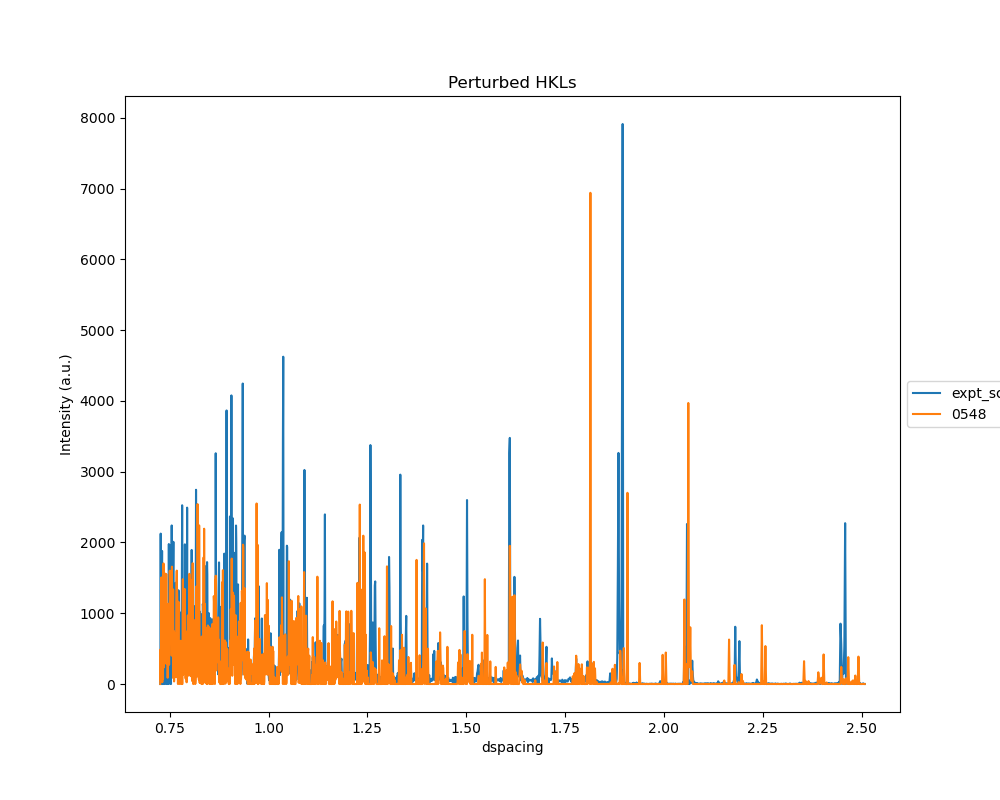

In [8]:
# load bin edges
bin_edges_path = os.path.join(cwd, 'gpu_binned_data', 'alpha_bin_edges_C0p0008.txt')
bin_edges = torch.tensor(np.loadtxt(bin_edges_path))

def get_expt_hkl_2(expt_path, bin_edges, scale=None):
    hkl = pd.read_csv(expt_path, sep='\s+', header = None, names = ['d','i'])
    hkl_sorted = hkl.sort_values(by=['d'], ascending=True)
    hkl_tensor = torch.tensor(hkl_sorted.values, dtype=torch.double)
    hkl_binned = bin_tensor(hkl_tensor, bin_edges, scale)
    return hkl_binned

hkl_0548_binned = torch.load(os.path.join(cwd, 'gpu_binned_data', 'cif0548.pt'), map_location='cpu')
hkl_expt_binned = torch.load(os.path.join(cwd, 'gpu_binned_data', 'expt_hkl_binned.pt'), map_location='cpu')
hkl_expt_binned_scale1 = get_expt_hkl_2(os.path.join(cwd, 'TOPAS', phase_name, 'experimental_refinement', 'd_Ip_expt_VC_P1_latparams_scale_1.dat'), bin_edges)

fig4, (hkl) = plt.subplots(1, figsize=(10,8))
fig4.subplots_adjust(hspace=.4)

# hkl.plot(bin_edges, hkl_expt_binned[0], label = f'expt')
hkl.plot(bin_edges, hkl_expt_binned_scale1, label = f'expt_scale')
hkl.plot(bin_edges, hkl_0548_binned[0], label = f'0548')
# hkl.plot(bin_edges, hkl_0548_binned[1], label = f'0548')
# hkl.plot(bin_edges, hkl_0548_binned[2], label = f'0548')


hkl.set_title(f'Perturbed HKLs')
hkl.set_xlabel('dspacing')
hkl.set_ylabel('Intensity (a.u.)')
hkl.legend(bbox_to_anchor = [1.0, .5], loc='center left')